In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [2]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [3]:
# column names that dont make sense:
# - uid
# - asin


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [6]:
df.describe()

,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?

2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

In [10]:
df["category"].unique()

array(['Hi-Fi Speakers', 'CD, Disc & Tape Players', 'Wearable Technology',
       'Light Bulbs', 'Bathroom Lighting',
       'Heating, Cooling & Air Quality', 'Coffee & Espresso Machines',
       'Lab & Scientific Products', 'Smart Speakers',
       'Motorbike Clothing', 'Motorbike Accessories',
       'Motorbike Batteries', 'Motorbike Boots & Luggage',
       'Motorbike Chassis', 'Handmade Home & Kitchen Products',
       'Hardware', 'Storage & Home Organisation',
       'Fireplaces, Stoves & Accessories', 'PC Gaming Accessories',
       'USB Gadgets', 'Blank Media Cases & Wallets', 'Car & Motorbike',
       'Boys', 'Sports & Outdoors', 'Microphones', 'String Instruments',
       'Karaoke Equipment', 'PA & Stage',
       'General Music-Making Accessories', 'Wind Instruments',
       'Handmade Gifts', 'Fragrances', 'Calendars & Personal Organisers',
       'Furniture & Lighting', 'Computer Printers', 'Ski Goggles',
       'Snowboards', 'Skiing Poles', 'Downhill Ski Boots',
       'Hiki

In [11]:
df["category"].nunique()

296

In [13]:
category_counts = df["category"].value_counts()
category_counts.head(5)

Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: category, dtype: int64

_______________________________________________________
Question:
Which are the top 5 most listed product categories?

Answer:
The top 5 categories are:
1. Sports & Outdoors
2. Beauty
3. Handmade Clothing, Shoes & Accessories
4. Bath & Body
5. Birthday Gifts
_______________________________________________________

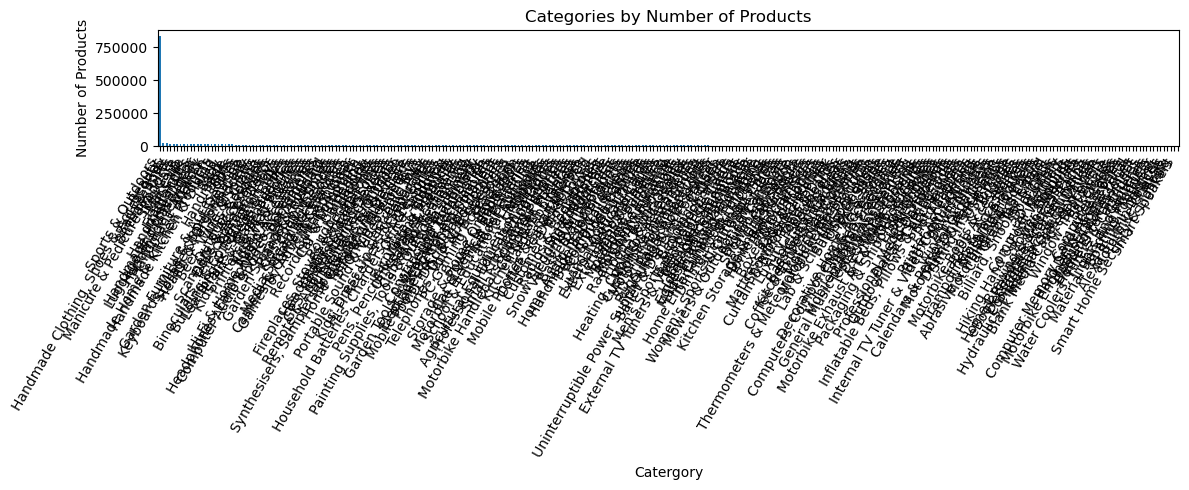

In [ ]:
plt.figure(figsize=(12,5))
category_counts.plot(kind="bar")
plt.title("Categories by Number of Products")
plt.xlabel("Catergory")
plt.ylabel("Number of Products")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
# wauw 😂

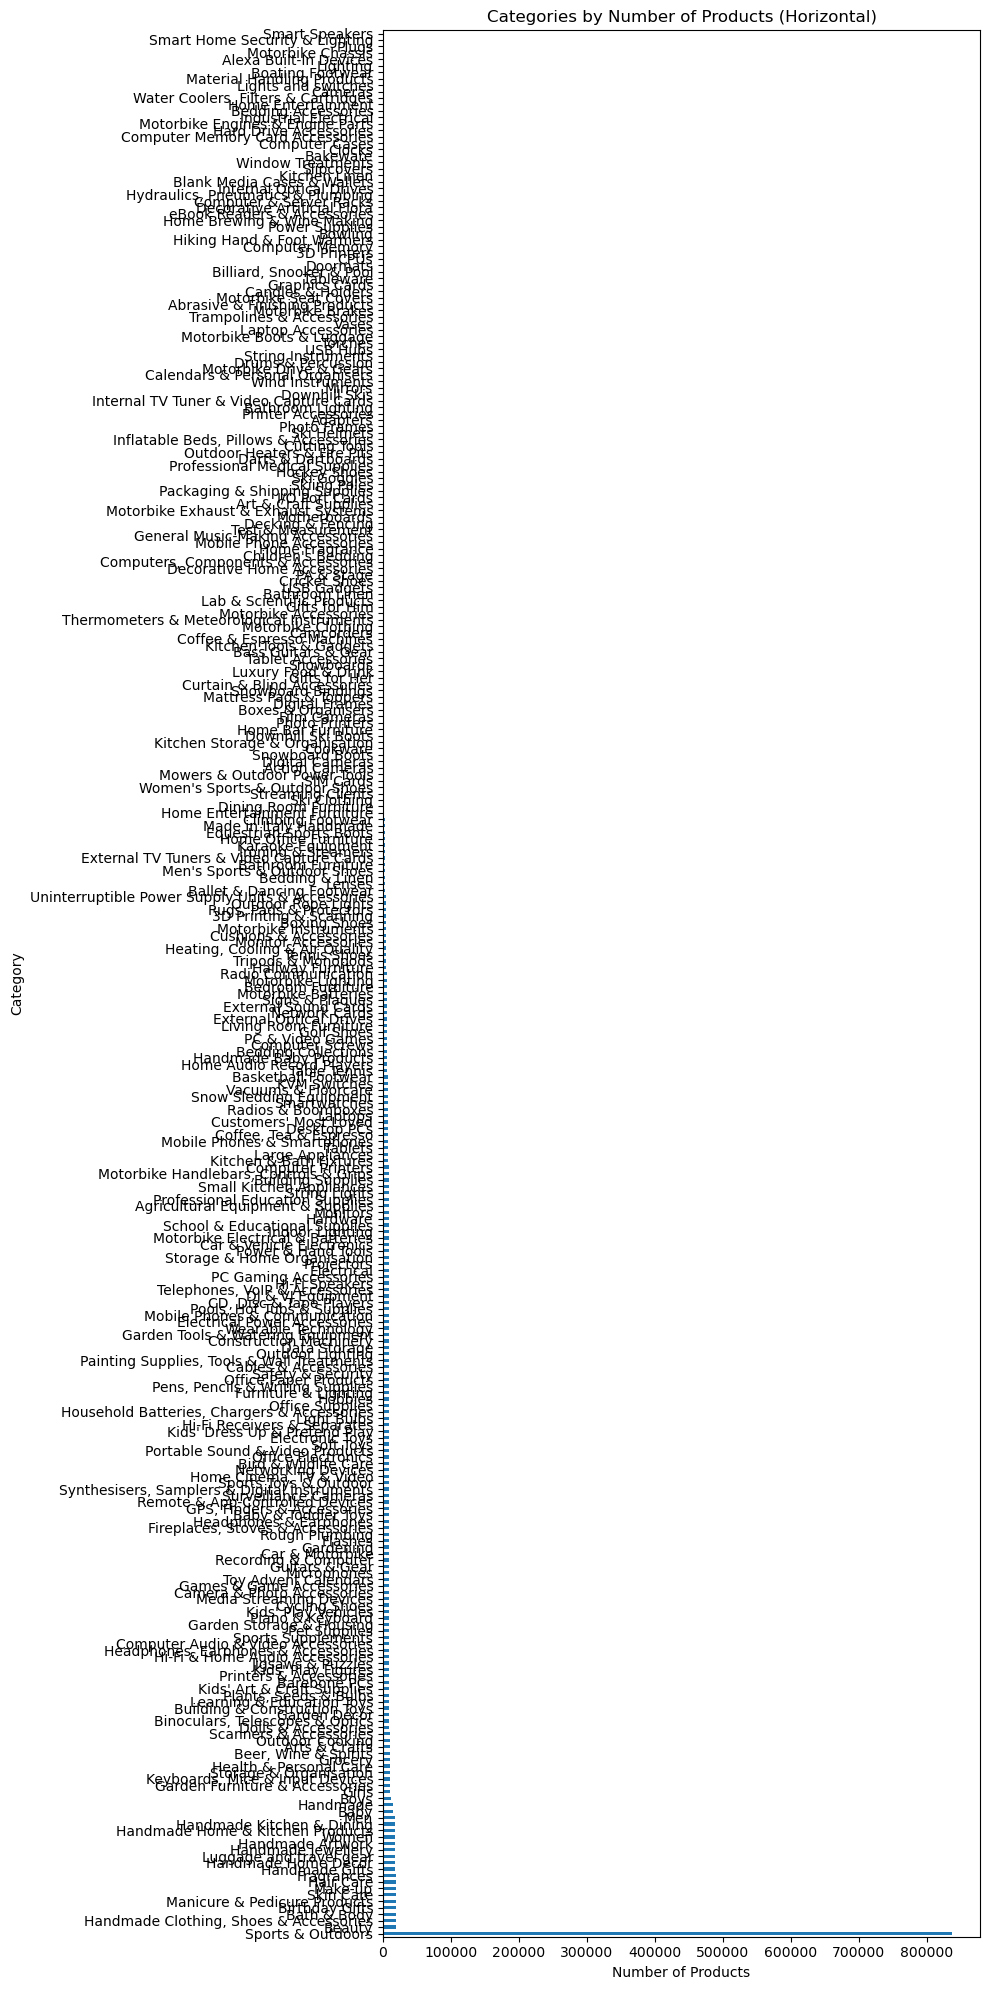

In [25]:
plt.figure(figsize=(10, 20))
category_counts.plot(kind="barh")
plt.title("Categories by Number of Products (Horizontal)")
plt.xlabel("Number of Products")
plt.ylabel("Category")
plt.tight_layout()
plt.show() 

In [ ]:
# again: wauw 😂

In [ ]:
category_top10 = category_counts.head(10)


In [18]:
category_top5 = category_counts.head(5)

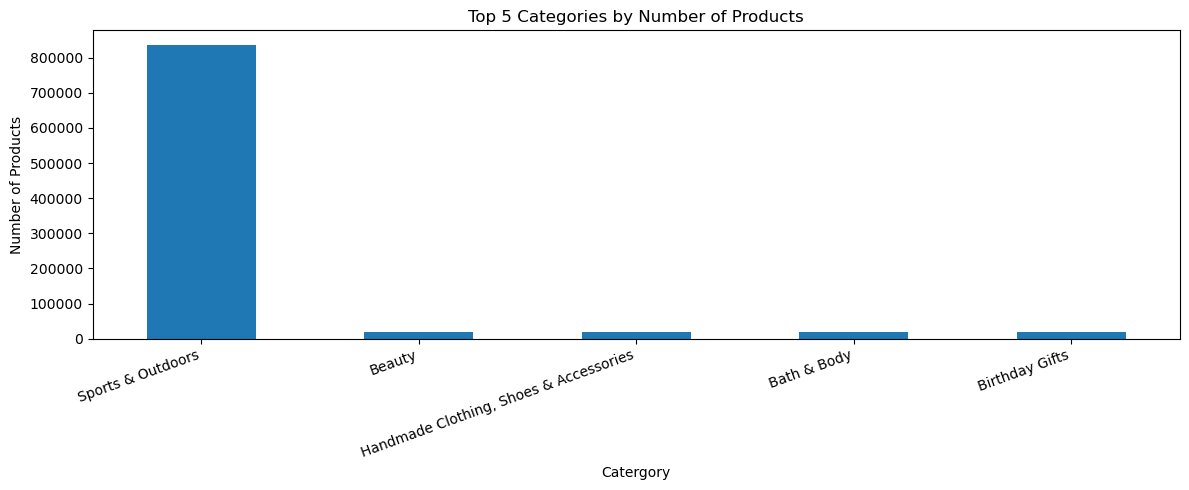

In [22]:
plt.figure(figsize=(12,5))
category_top5.plot(kind="bar")
plt.title("Top 5 Categories by Number of Products")
plt.xlabel("Catergory")
plt.ylabel("Number of Products")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

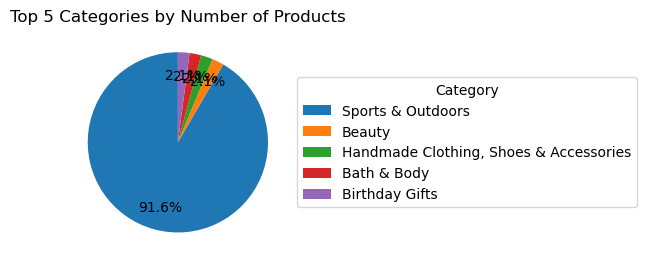

In [29]:
plt.figure(figsize=(6, 6))
category_top5.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90,
    labels=None,
    pctdistance=0.75
)
plt.ylabel("")
plt.title("Top 5 Categories by Number of Products")
plt.legend(
    category_top5.index,
    title="Category",
    loc="center left",
    bbox_to_anchor=(1.0, 0.5)
)
plt.tight_layout()
plt.show()

/var/folders/b3/pxqr_2n925q29gqmh_spc70m0000gn/T/ipykernel_69241/2761731185.py:17: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


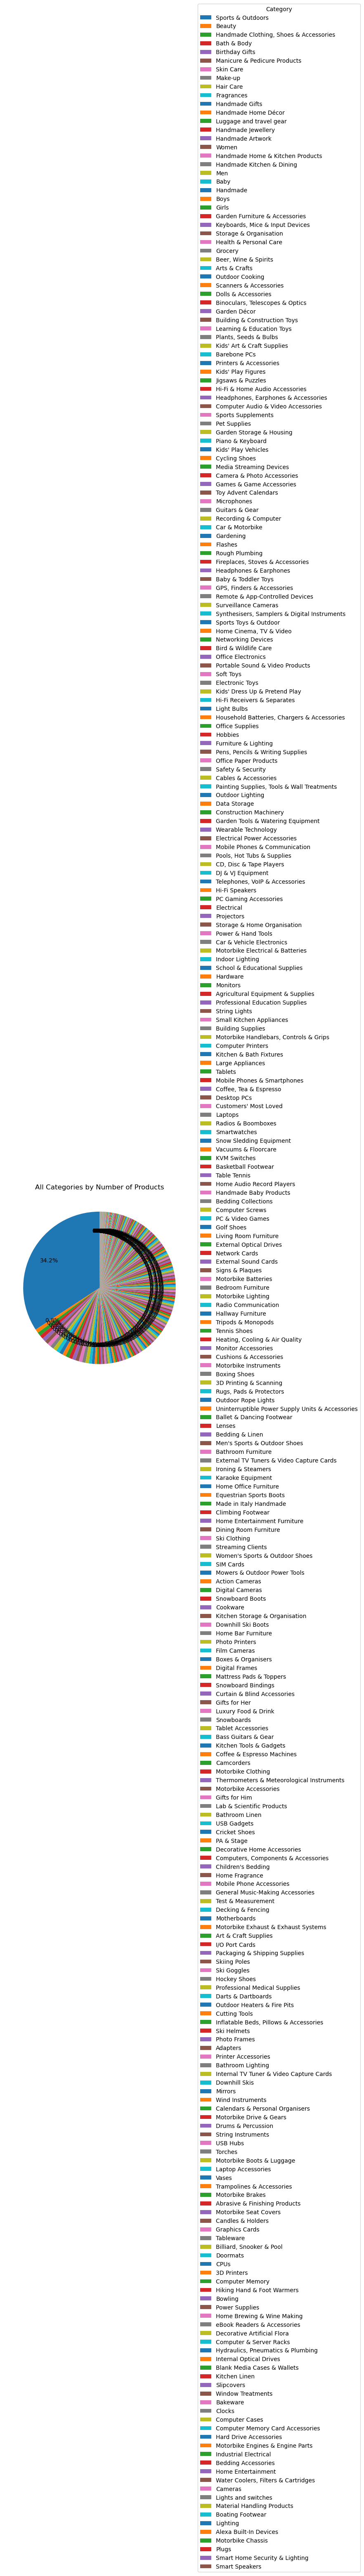

In [31]:
plt.figure(figsize=(6, 6))
category_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90,
    labels=None,
    pctdistance=0.75
)
plt.ylabel("")
plt.title("All Categories by Number of Products")
plt.legend(
    category_counts.index,
    title="Category",
    loc="center left",
    bbox_to_anchor=(1.0, 0.5)
)
plt.tight_layout()
plt.show()

_______________________________________________________
Question: 
Does any category dominate the listings?

Answer: 
Yes, the Sports & Outdoors clearly dominates the listings with 91.6% of the products.
_______________________________________________________

_______________________________________________________
Business Question: 
1. What are the most popular product categories on Amazon UK
2. and how do they compare in terms of listing frequency?

Answer:
The 5 most popular product categories on Amazon UK are:
1. Sports & Outdoors
2. Beauty
3. Handmade Clothing, Shoes & Accessories
4. Bath & Body
5. Birthday Gifts

A very large difference between the category counts of products.
The category "Sports & Outdoors" has 91.6% of the shares within the Top 5 and 34.2% shares across all categories.
It clearly dominates the dataset. This indicates a highly skewed category distribution.
_______________________________________________________

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

In [32]:
df["price"].isna().sum()

0

In [34]:
(df["price"] == 0).sum()

20

In [ ]:
# 20 products that are listed with a price of 0. Strange or just give aways?

In [35]:
df["price"].max()

100000.0

In [ ]:
# seems very high

In [37]:
df.sort_values(by="price", ascending=False).head(10)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
2008013,2259336,B091F5Y3CT,HB FBA Test Treadmill,0.0,0,100000.00,False,0,Sports & Outdoors
1987238,2235317,B0CDVKNBRV,Générique L.A 350° - I5 11400F - RTX 3050 8G -...,0.0,0,77752.00,False,0,Desktop PCs
1905315,2136904,B0CJSNFYVM,Abaodam decor christmas ornaments Desk Ornamen...,0.0,0,24674.59,False,0,Garden Storage & Housing
1408966,1551117,B0CHT331TN,BM4445-FI1-01200R10-03-E03 Driver,0.0,0,23482.73,False,0,Scanners & Accessories
319555,340285,B0CHYG6MNW,HEDUSA Halloween 3D Holographic Fan 3D Hologra...,0.0,0,22933.42,False,0,Projectors
1490285,1651376,B08M36F6S2,YXHUI Kids Girls Figure Skating Dress Long Sle...,0.0,0,21999.00,False,0,Sports & Outdoors
1490286,1651377,B08M31N65K,YXHUI Kids Girls Figure Skating Dress Long Sle...,0.0,0,21999.00,False,0,Sports & Outdoors
1907272,2138946,B0C8MVQB8R,Outdoor Furniture Wood Porch Swing Black Brown...,0.0,0,21464.82,False,0,Garden Storage & Housing
1907271,2138945,B0C8MWJRSH,Outdoor Furniture Wood Porch Swing Black Brown...,0.0,0,21464.82,False,0,Garden Storage & Housing
1907273,2138947,B0C8MVKYW2,Outdoor Furniture Wood Porch Swing Black Brown...,0.0,0,21464.82,False,0,Garden Storage & Housing


In [44]:
price_mean = df["price"].mean()
price_median = df["price"].median()
price_mode = df["price"].mode()[0]

In [39]:
price_mean

89.24380943923663

In [40]:
price_median

19.09

In [45]:
price_mode

9.99

_______________________________________________________
Question:
1. What's the average price point of products listed?
2. How does this compare with the most common price point (mode)?

Answer:
The average is £89.24. Only this is biased because of a few products that have very high pricing.
The median would be a better average. The median is £19.09. meaning that half of all products are priced below £19.

The mode/most common price is £9.99 and is close to the median. The difference between them is only +/- £10
_______________________________________________________

In [53]:
price_variance = df["price"].var()
price_std = df["price"].std()
price_min = df["price"].min()
price_max = df["price"].max()
price_range = price_max - price_min

q1 = df["price"].quantile(0.25)
q3 = df["price"].quantile(0.75)
price_iqr = q3 - q1


In [52]:
price_variance

119445.4853225653

In [47]:
price_std

345.6088617535223

In [48]:
price_range

100000.0

In [49]:
q1

9.99

In [50]:
q3

45.99

In [51]:
price_iqr

36.0

_______________________________________________________
Question:
How varied are the product prices? Are there any indicators of a significant spread in prices?

Answer:
Product prices show extreme variability. The price range is £100000 while 50% of the products are prices between £9.99 and £45.99.
_______________________________________________________

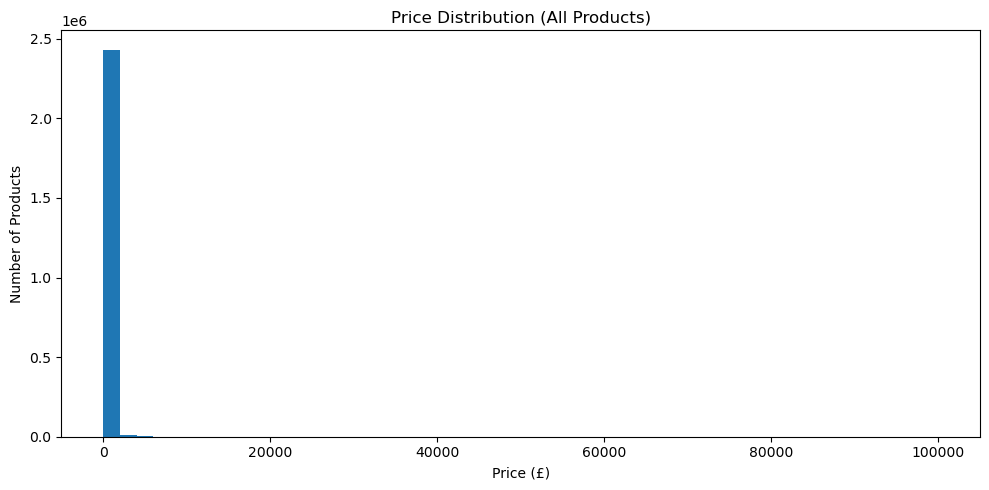

In [56]:
plt.figure(figsize=(10, 5))
plt.hist(df["price"], bins=50)
plt.title("Price Distribution (All Products)")
plt.xlabel("Price (£)")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.show()

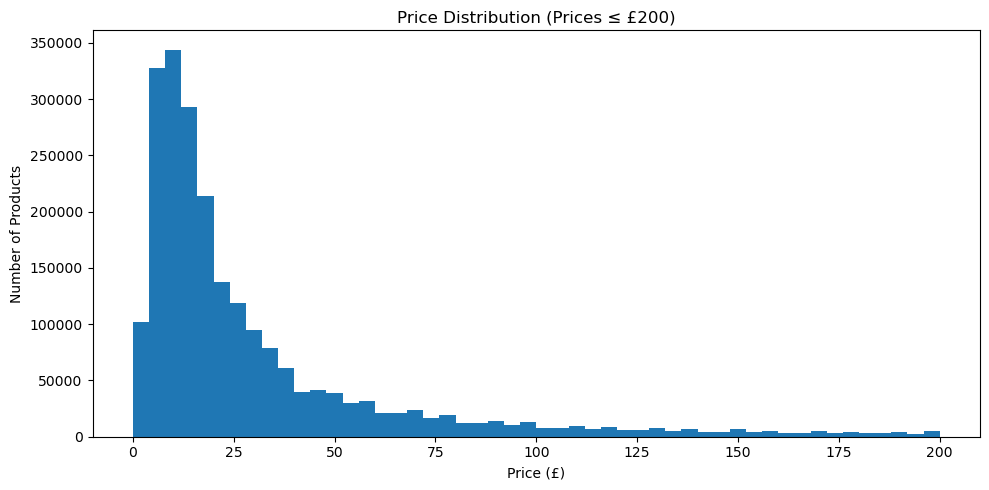

In [57]:
plt.figure(figsize=(10, 5))
plt.hist(df.loc[df["price"] <= 200, "price"], bins=50)
plt.title("Price Distribution (Prices ≤ £200)")
plt.xlabel("Price (£)")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.show()


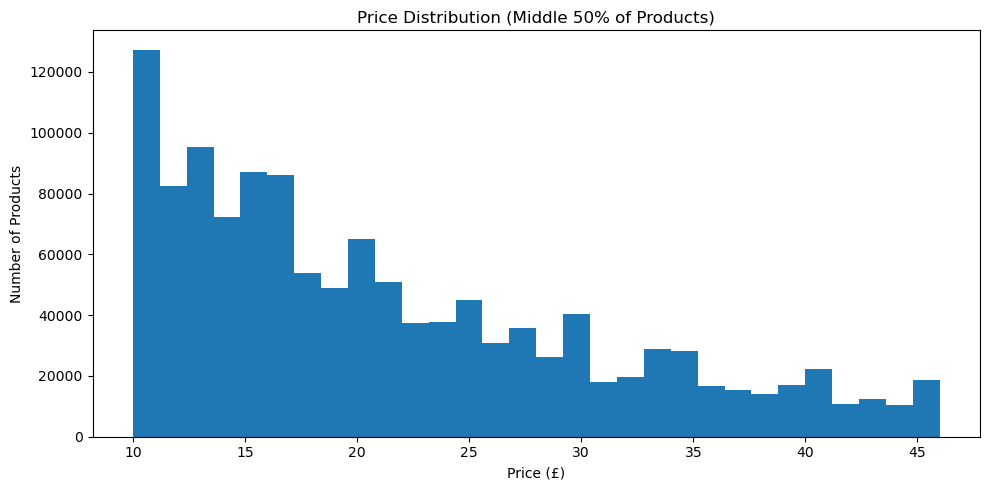

In [58]:
middle_50 = df.loc[
    (df["price"] >= q1) & (df["price"] <= q3),
    "price"
]

plt.figure(figsize=(10, 5))
plt.hist(middle_50, bins=30)
plt.title("Price Distribution (Middle 50% of Products)")
plt.xlabel("Price (£)")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.show()


_______________________________________________________
Question:
If its hard to read these diagrams, think why this is, and explain how it could be solved.

Answer:
It is hard to read because it is hard to see how hight the number of products actually is. This could be solved by making more histograms with smaller ranges. Or to put a blokked background so you can see more clearly where the "bars" actually end.
_______________________________________________________

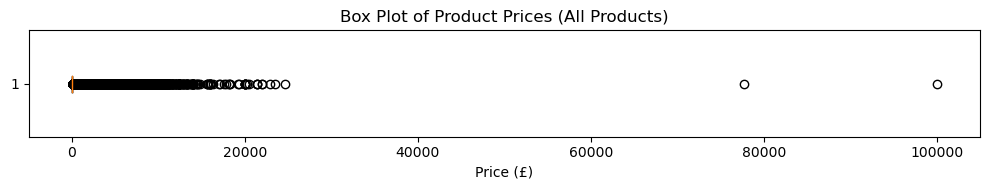

In [59]:
plt.figure(figsize=(10, 2))
plt.boxplot(df["price"], vert=False)
plt.title("Box Plot of Product Prices (All Products)")
plt.xlabel("Price (£)")
plt.tight_layout()
plt.show()


_______________________________________________________
Question:
Are there products that are priced significantly higher than the rest?

Answer:
Yes. One at 100000 and one around 80000. 
Also some outliers in the 20000 till +/- 25000 range. But these look small in comparison with the 2 bigest once (the 100000 and 80000)
_______________________________________________________

_______________________________________________________
Business Question:
How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

Answer:
Product prices show extreme variability. The price range is £100000 while 50% of the products are prices between £9.99 and £45.99.
Amazon UK has 2 products that are have extreme high pricing (£100000 and £77752)
_______________________________________________________

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

In [60]:
stars_mean_all = df["stars"].mean()
stars_median_all = df["stars"].median()
stars_mode_all = df["stars"].mode()[0]

stars_mean_all


2.152836472966065

In [61]:
stars_median_all

0.0

In [62]:
stars_mode_all

0.0

In [ ]:
# median and mode are 0. Lets try without non rated products

In [63]:
rated = df.loc[df["stars"] > 0, "stars"]

stars_mean_rated = rated.mean()
stars_median_rated = rated.median()
stars_mode_rated = rated.mode()[0]

stars_mean_rated, stars_median_rated, stars_mode_rated


(4.31916076222691, 4.4, 4.5)

In [64]:
# better

___
Question:
How do customers generally rate products? Is there a common trend?

Answer:
The mean, median and mode all point to a regular distribution of 4.3 till 4.5 stars. As long as we are not counting the products that dont have any ratings!
___

In [66]:
stars_var_rated = rated.var()
stars_std_rated = rated.std()

q1_r = rated.quantile(0.25)
q3_r = rated.quantile(0.75)
iqr_r = q3_r - q1_r

print(f"Variance of rated stars: {stars_var_rated}")
print(f"Standard deviation of rated stars: {stars_std_rated}")
print(f"First quartile of rated stars: {q1_r}")
print(f"Third quartile of rated stars: {q3_r}")
print(f"IQR of rated stars: {iqr_r}")


Variance of rated stars: 0.30834337523805183
Standard deviation of rated stars: 0.5552867504614637
First quartile of rated stars: 4.1
Third quartile of rated stars: 4.6
IQR of rated stars: 0.5


___
Question:
Are the ratings consistent, or is there a wide variation in customer feedback?


Answer:
The ratings are consistent.
___

In [67]:
skew_r = rated.skew()
kurt_r = rated.kurt()

skew_r, kurt_r


(-2.3795681122127945, 9.78193769066435)

In [ ]:
# negative skew (-2.38) means tail on the left
# 9.78 is high for a kurtosis, meaning heavy tails

___
Question:
Are the ratings normally distributed, or do they lean towards higher or lower values?

Answer:
No, we have a heavy tail towards the left. Which is logical since the rating go from 0 to 5 and the average ratings are between 4 and 5 stars. That only leaves space on the left side, the rating from 0 till 4.
___

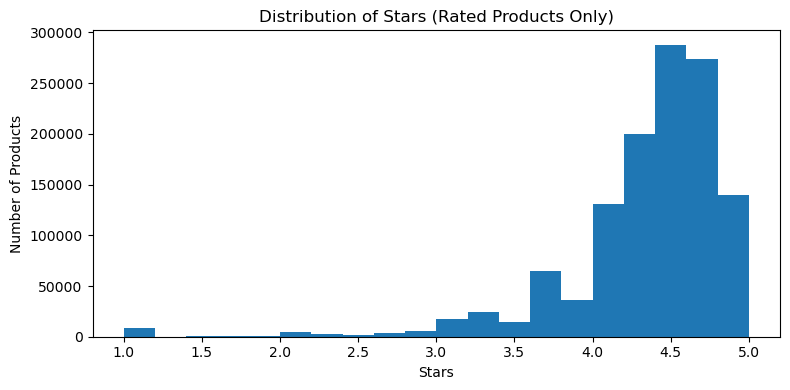

In [68]:
plt.figure(figsize=(8, 4))
plt.hist(rated, bins=20)
plt.title("Distribution of Stars (Rated Products Only)")
plt.xlabel("Stars")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.show()


___
Question:
Is there a specific rating that is more common?

Answer:
Yes, 4.5 is at the top with +/- 4.7 not far behind
___

___
Business Question:
How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

Answer:
Most of the customers give the products rating between 4 and 5 stars
___